# Reconnaissance des billets tunisiens (5, 10, 20, 50 DT)

**Projet de vision par ordinateur** : photos de billets prises au téléphone (tenus à la main, pliés, recto/verso, fonds variés).

Chaîne étudiée :
1. **Méthode classique** : segmentation du billet (flou, K-means couleur / seuillage Otsu / GrabCut, morphologie, composantes connexes).
2. **Apprentissage automatique** : caractéristiques couleur et texture (HSV, Lab, LBP, HOG) + SVM et Random Forest.
3. **Apprentissage profond** : transfer learning MobileNetV2 + Grad-CAM.
4. **Évaluation critique** : ablations, robustesse, doublons train/test, courbes d'apprentissage, analyse des erreurs.

## 0. Données et exploration

In [1]:
# Téléchargement du dataset Kaggle
try:
    import truststore; truststore.inject_into_ssl()  # certificats système (utile derrière un antivirus / proxy)
except ImportError:
    pass
import kagglehub

path = kagglehub.dataset_download("majdihbibi/tunisian-banknotes")
print("Dossier du dataset :", path)

C:\Users\Bouattour\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dossier du dataset : C:\Users\Bouattour\.cache\kagglehub\datasets\majdihbibi\tunisian-banknotes\versions\1


In [2]:
import os, glob, collections
racine = path
exts = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')
fichiers = [p for p in glob.glob(os.path.join(racine, '**', '*'), recursive=True) if os.path.isfile(p)]
imgs = [p for p in fichiers if p.lower().endswith(exts)]
autres = [p for p in fichiers if not p.lower().endswith(exts)]
print('Total fichiers:', len(fichiers), '| images:', len(imgs), '| autres:', len(autres))
compte = collections.Counter(os.path.relpath(os.path.dirname(p), racine) for p in imgs)
print('\n'.join(f'{k}: {v}' for k, v in sorted(compte.items())))

Total fichiers: 662 | images: 662 | autres: 0
Dataset\test\10dt: 37
Dataset\test\20dt: 34
Dataset\test\50dt: 29
Dataset\test\5dt: 34
Dataset\train\10dt: 145
Dataset\train\20dt: 134
Dataset\train\50dt: 116
Dataset\train\5dt: 133


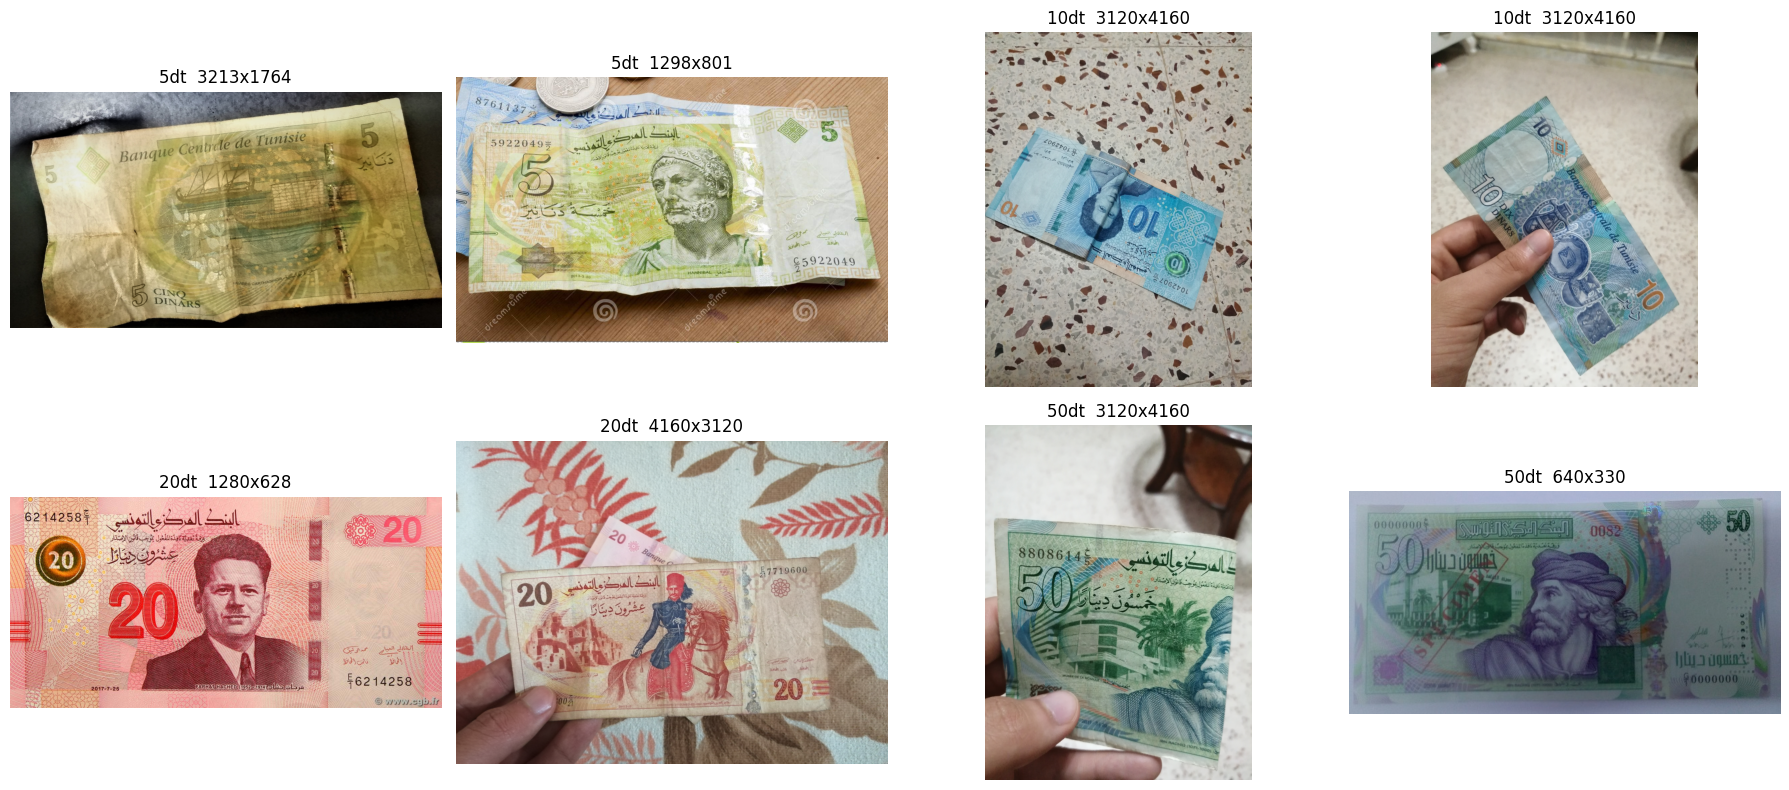

In [3]:
# Aperçu : 2 images par classe (pleine résolution)
import cv2, random, numpy as np, matplotlib.pyplot as plt
random.seed(0)
ech = [random.choice([p for p in imgs if os.path.basename(os.path.dirname(p)) == c])
       for c in ['5dt', '10dt', '20dt', '50dt'] for _ in range(2)]
plt.figure(figsize=(18, 8))
for i, p in enumerate(ech):
    im = cv2.imread(p)
    plt.subplot(2, 4, i + 1)
    plt.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
    plt.title(f"{os.path.basename(os.path.dirname(p))}  {im.shape[1]}x{im.shape[0]}")
    plt.axis('off')
plt.tight_layout(); plt.show()

In [4]:
# Hétérogénéité des sources : photos de téléphone (grandes) vs images web / scans (petites)
import pandas as pd
from PIL import Image

tailles = pd.DataFrame([(os.path.basename(os.path.dirname(os.path.dirname(p))), os.path.basename(os.path.dirname(p)),
                         *Image.open(p).size) for p in imgs], columns=['split', 'classe', 'largeur', 'hauteur'])
tailles['source'] = np.where(tailles[['largeur', 'hauteur']].max(axis=1) >= 2000, 'photo', 'web/scan')
print(pd.crosstab([tailles.split, tailles.classe], tailles.source, margins=True))

source        photo  web/scan  All
split classe                      
test  10dt       29         8   37
      20dt       31         3   34
      50dt       15        14   29
      5dt         2        32   34
train 10dt      113        32  145
      20dt      111        23  134
      50dt       41        75  116
      5dt        16       117  133
All             358       304  662


## 1. Chargement des images
Les photos (~3000x4000) sont lues directement réduites (côté max 512 px) pour accélérer tout le reste du traitement.

In [5]:
import os, glob, time
import numpy as np
import cv2
import matplotlib.pyplot as plt

RACINE = os.path.join(path, 'Dataset')
CLASSES = ['5dt', '10dt', '20dt', '50dt']
TAILLE_MAX = 512

def charger_image(chemin, taille_max=TAILLE_MAX):
    # lecture directement réduite (plus rapide sur les photos 4000x3000) ;
    # les petites images (web, scans) sont relues en pleine résolution
    img = cv2.imread(chemin, cv2.IMREAD_REDUCED_COLOR_4)
    if max(img.shape[:2]) < taille_max:
        img = cv2.imread(chemin)
    h, w = img.shape[:2]
    s = taille_max / max(h, w)
    interp = cv2.INTER_AREA if s < 1 else cv2.INTER_CUBIC
    return cv2.resize(img, (round(w * s), round(h * s)), interpolation=interp)

def charger_split(split):
    X, y, chemins = [], [], []
    for i, c in enumerate(CLASSES):
        for p in sorted(glob.glob(os.path.join(RACINE, split, c, '*'))):
            X.append(charger_image(p))
            y.append(i)
            chemins.append(p)
    return X, np.array(y), chemins

t0 = time.time()
X_train, y_train, p_train = charger_split('train')
X_test, y_test, p_test = charger_split('test')
print(f'train : {len(X_train)} images | test : {len(X_test)} images | {time.time() - t0:.0f} s')
print('répartition train :', np.bincount(y_train), '| test :', np.bincount(y_test))

train : 528 images | test : 134 images | 32 s
répartition train : [133 145 134 116] | test : [34 37 34 29]


## 2. Segmentation classique du billet

Objectif : isoler le billet du fond et de la main avant d'extraire des caractéristiques.

Trois méthodes classiques sont comparées (toutes sur l'image réduite) :
- **K-means couleur** : flou gaussien → K-means dans l'espace Lab (k = 3) → cluster le plus présent au centre et le moins présent sur les bords ;
- **Otsu sur la saturation** : les billets sont colorés, alors que beaucoup de fonds (murs, tables, papier) sont peu saturés ;
- **GrabCut** : initialisé par un rectangle couvrant presque toute l'image (marge de 2 %), car le billet remplit souvent le cadre.

Post-traitement commun : fermeture puis ouverture morphologiques → plus grande composante connexe → rectangle orienté minimal (`minAreaRect`) → redressement du billet en 256x128 px.
En cas d'échec (masque trop petit / trop grand), on se replie sur le centre de l'image.

In [25]:
TAILLE_CROP = (256, 128)          # billet redressé (largeur, hauteur)
NOYAU = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))

def score_central(masque):
    # fraction du masque au centre moins fraction sur les bords
    h, w = masque.shape
    centre = masque[h // 4: 3 * h // 4, w // 4: 3 * w // 4].mean()
    bord = np.concatenate([masque[:h // 10].ravel(), masque[-h // 10:].ravel(),
                           masque[:, :w // 10].ravel(), masque[:, -w // 10:].ravel()]).mean()
    return centre - bord

def masque_kmeans(img, k=3):
    flou = cv2.GaussianBlur(img, (7, 7), 0)
    lab = cv2.cvtColor(flou, cv2.COLOR_BGR2LAB)
    petit = cv2.resize(lab, None, fx=0.25, fy=0.25, interpolation=cv2.INTER_AREA)
    Z = petit.reshape(-1, 3).astype(np.float32)
    critere = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 20, 1.0)
    cv2.setRNGSeed(0)
    _, lab_k, _ = cv2.kmeans(Z, k, None, critere, 3, cv2.KMEANS_PP_CENTERS)
    lab_k = lab_k.reshape(petit.shape[:2])
    c = max(range(k), key=lambda j: score_central((lab_k == j).astype(float)))
    m = (lab_k == c).astype(np.uint8) * 255
    return cv2.resize(m, (img.shape[1], img.shape[0]), interpolation=cv2.INTER_NEAREST)

def masque_otsu(img):
    flou = cv2.GaussianBlur(img, (7, 7), 0)
    s = cv2.cvtColor(flou, cv2.COLOR_BGR2HSV)[:, :, 1]
    _, m = cv2.threshold(s, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return m

def masque_grabcut(img, marge=0.02, iters=3):
    # calcul sur l'image réduite de moitié (4x plus rapide), masque ré-agrandi ensuite
    petit = cv2.resize(img, None, fx=0.5, fy=0.5, interpolation=cv2.INTER_AREA)
    h, w = petit.shape[:2]
    rect = (int(w * marge), int(h * marge), int(w * (1 - 2 * marge)), int(h * (1 - 2 * marge)))
    m = np.zeros((h, w), np.uint8)
    bgd, fgd = np.zeros((1, 65)), np.zeros((1, 65))
    cv2.grabCut(petit, m, rect, bgd, fgd, iters, cv2.GC_INIT_WITH_RECT)
    m = np.where((m == cv2.GC_FGD) | (m == cv2.GC_PR_FGD), 255, 0).astype(np.uint8)
    return cv2.resize(m, (img.shape[1], img.shape[0]), interpolation=cv2.INTER_NEAREST)

def nettoyer(m):
    # fermeture (combler les trous) puis ouverture (retirer le bruit), puis plus grande composante
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, NOYAU)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, NOYAU)
    n, lab, stats, _ = cv2.connectedComponentsWithStats(m)
    if n <= 1:
        return np.zeros_like(m)
    i = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    m = (lab == i).astype(np.uint8) * 255
    # remplissage des trous internes (motifs du billet)
    cnts, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    return cv2.drawContours(np.zeros_like(m), cnts, -1, 255, cv2.FILLED)

def redresser(img, m):
    # rectangle orienté minimal -> billet redressé à l'horizontale ; None si masque non plausible
    frac = m.mean() / 255
    if not 0.08 < frac < 0.9:
        return None, None
    cnts, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    box = cv2.boxPoints(cv2.minAreaRect(max(cnts, key=cv2.contourArea)))
    # coins triés dans le sens horaire, en partant du coin haut-gauche
    c = box.mean(0)
    src = box[np.argsort(np.arctan2(box[:, 1] - c[1], box[:, 0] - c[0]))]
    src = np.roll(src, -np.argmin(src.sum(1)), axis=0).astype(np.float32)
    if np.linalg.norm(src[3] - src[0]) > np.linalg.norm(src[1] - src[0]):
        src = np.roll(src, -1, axis=0)   # billet vertical : grand côté mis à l'horizontale
    W, H = TAILLE_CROP
    dst = np.float32([[0, 0], [W - 1, 0], [W - 1, H - 1], [0, H - 1]])
    crop = cv2.warpPerspective(img, cv2.getPerspectiveTransform(src, dst), TAILLE_CROP)
    return crop, box

def recadrage_central(img, frac=0.7):
    h, w = img.shape[:2]
    y0, x0 = int(h * (1 - frac) / 2), int(w * (1 - frac) / 2)
    c = img[y0:h - y0, x0:w - x0]
    if c.shape[0] > c.shape[1]:
        c = cv2.rotate(c, cv2.ROTATE_90_CLOCKWISE)
    return cv2.resize(c, TAILLE_CROP, interpolation=cv2.INTER_AREA)

METHODES = {'kmeans': masque_kmeans, 'otsu': masque_otsu, 'grabcut': masque_grabcut}

def segmenter(img, methode='kmeans'):
    # renvoie (billet redressé, masque, boîte, repli utilisé ?)
    m = nettoyer(METHODES[methode](img))
    crop, box = redresser(img, m)
    if crop is None:
        # masque trop grand : le billet remplit le cadre (scan) -> image entière ; sinon centre
        return recadrage_central(img, 1.0 if m.mean() / 255 >= 0.9 else 0.7), m, None, True
    return crop, m, box, False

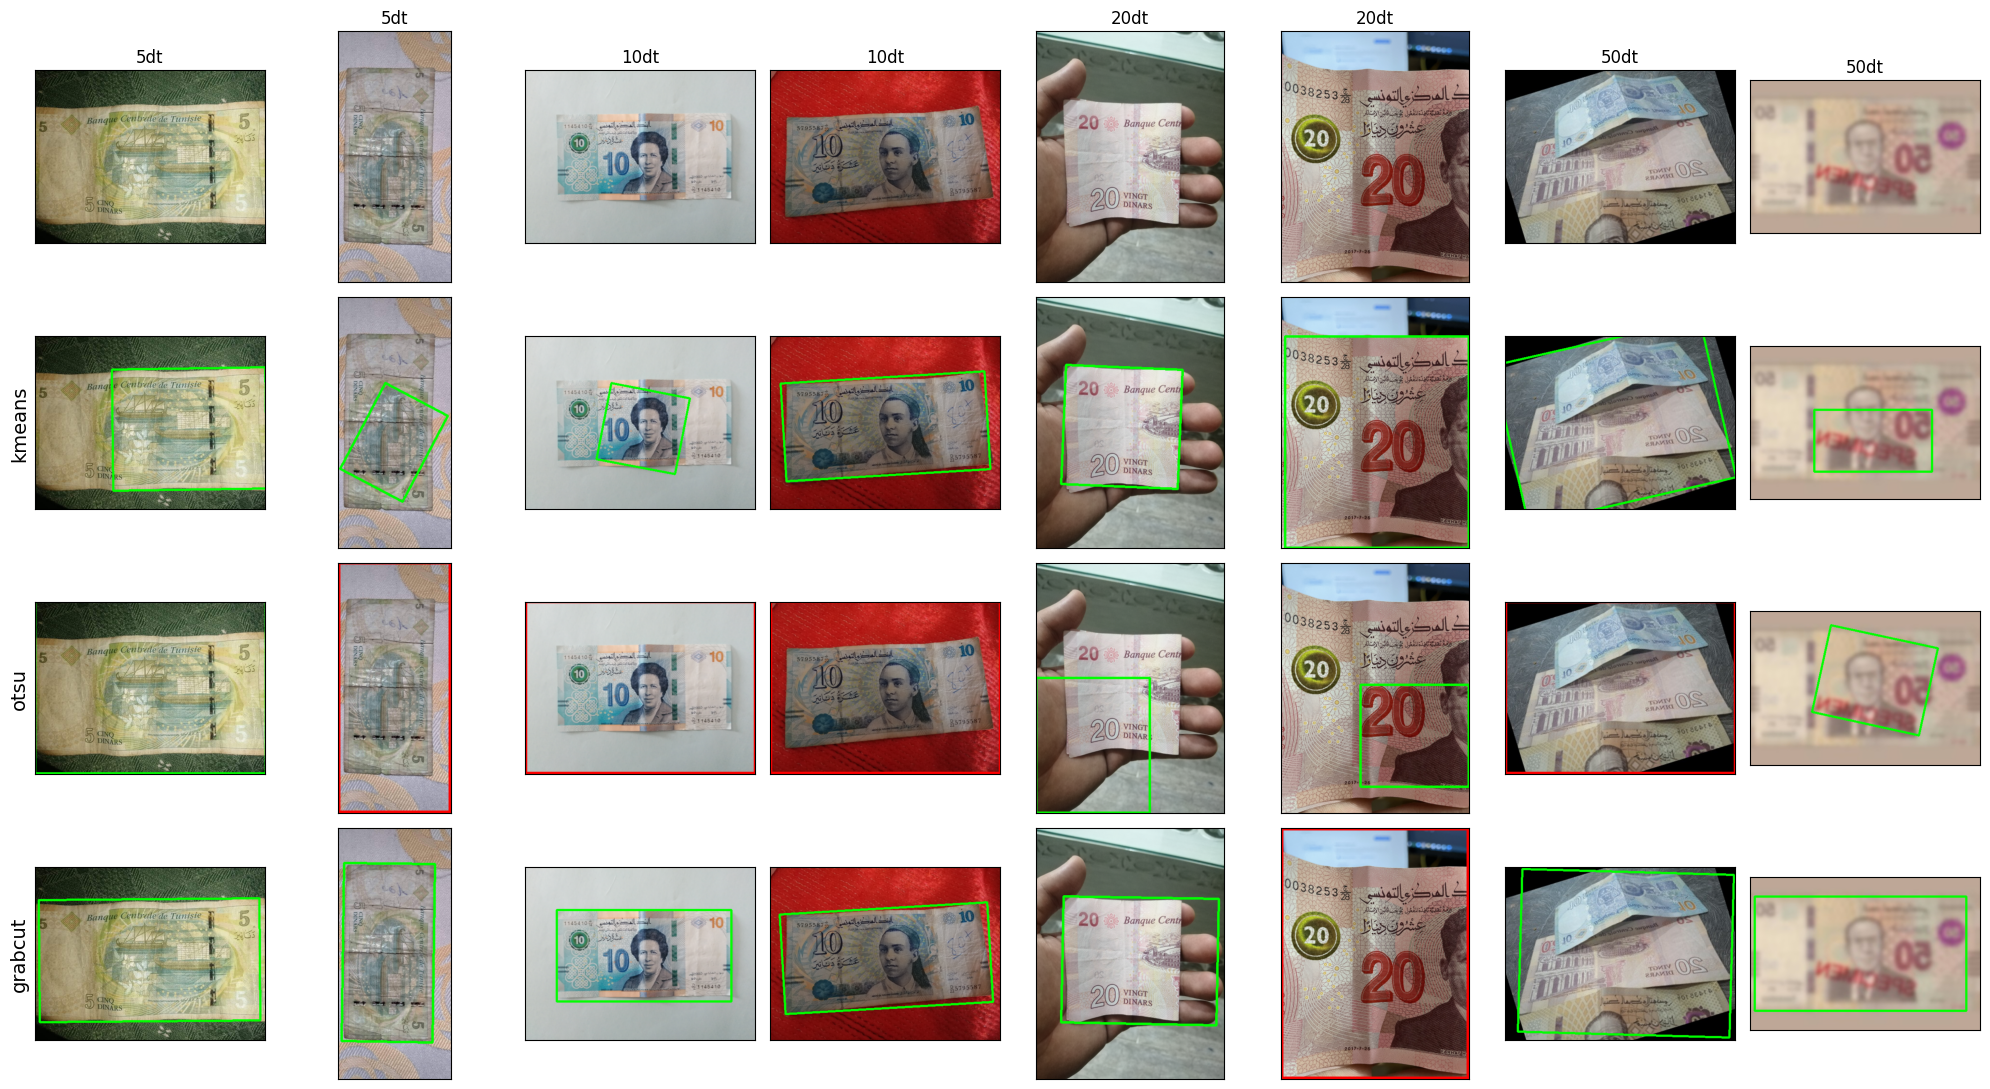

In [26]:
# Comparaison visuelle des 3 méthodes sur des images du train (contour vert = billet détecté, rouge = repli)
rng = np.random.default_rng(1)
idx_vis = [rng.choice(np.where(y_train == c)[0]) for c in range(4) for _ in range(2)]

fig, ax = plt.subplots(len(METHODES) + 1, len(idx_vis), figsize=(20, 11))
for j, i in enumerate(idx_vis):
    img = X_train[i]
    ax[0, j].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax[0, j].set_title(CLASSES[y_train[i]])
    for r, meth in enumerate(METHODES, start=1):
        crop, m, box, repli = segmenter(img, meth)
        vis = img.copy()
        if box is not None:
            cv2.drawContours(vis, [box.astype(int)], -1, (0, 255, 0), 4)
        else:
            cv2.rectangle(vis, (0, 0), (vis.shape[1] - 1, vis.shape[0] - 1), (0, 0, 255), 8)
        ax[r, j].imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
        ax[r, 0].set_ylabel(meth, fontsize=14)
for a in ax.ravel():
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

In [27]:
# Recadrage de toutes les images avec chaque méthode (+ image entière comme référence)
from joblib import Parallel, delayed

def forme(m):
    # rectangularité (aire du masque / aire du rectangle orienté) et allongement (grand côté / petit côté)
    cnts, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not cnts:
        return 0.0, 0.0
    c = max(cnts, key=cv2.contourArea)
    _, (w, h), _ = cv2.minAreaRect(c)
    if min(w, h) == 0:
        return 0.0, 0.0
    return cv2.contourArea(c) / (w * h), max(w, h) / min(w, h)

def recadrer_tout(X, methode):
    # renvoie (billets redressés, repli, rectangularité, allongement)
    if methode == 'entiere':
        return np.stack([recadrage_central(img, 1.0) for img in X]), np.zeros(len(X), bool), None, None
    res = Parallel(n_jobs=-1, prefer='threads')(delayed(segmenter)(img, methode) for img in X)
    formes = np.array([forme(m) for _, m, _, _ in res])
    return np.stack([r[0] for r in res]), np.array([r[3] for r in res]), formes[:, 0], formes[:, 1]

crops = {}
for meth in ['entiere', *METHODES]:
    t0 = time.time()
    crops[meth] = {'train': recadrer_tout(X_train, meth), 'test': recadrer_tout(X_test, meth)}
    print(f'{meth:8s} : {time.time() - t0:5.1f} s pour 662 images (8 threads)')

entiere  :   1.6 s pour 662 images (8 threads)
kmeans   :   3.9 s pour 662 images (8 threads)
otsu     :   1.7 s pour 662 images (8 threads)
grabcut  :  51.2 s pour 662 images (8 threads)


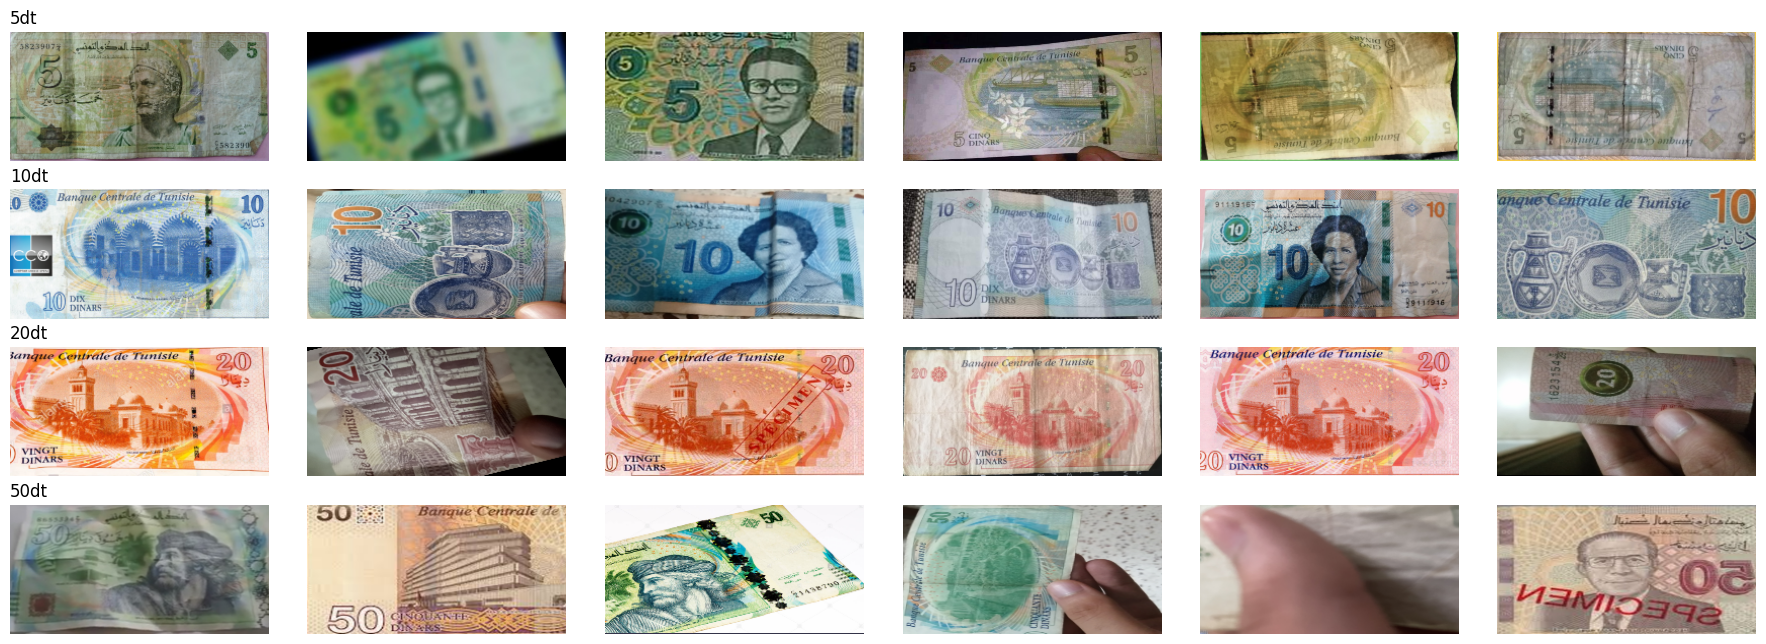

In [28]:
# Billets redressés (GrabCut) : 6 exemples par classe
fig, ax = plt.subplots(4, 6, figsize=(18, 6.5))
for c in range(4):
    for j, i in enumerate(np.where(y_train == c)[0][::23][:6]):
        ax[c, j].imshow(cv2.cvtColor(crops['grabcut']['train'][0][i], cv2.COLOR_BGR2RGB)); ax[c, j].axis('off')
    ax[c, 0].set_title(CLASSES[c], loc='left')
plt.tight_layout(); plt.show()

### Évaluation de la segmentation

Le dataset ne contient pas de masques de référence : on ne peut pas calculer d'IoU. On évalue donc la segmentation de deux façons :
1. **Critère de forme** (sans annotation) : un billet est un rectangle d'allongement ≈ 2 (longueur ≈ 2 x largeur). Une segmentation est jugée **plausible** si elle n'a pas déclenché le repli, si le masque remplit bien son rectangle orienté (rectangularité ≥ 0,85) et si l'allongement est compris entre 1,5 et 2,7 (billet un peu plié ou en perspective).
2. **Critère de tâche** (section 3) : la précision de classification obtenue avec chaque méthode.

In [29]:
import pandas as pd

lignes = []
for meth in METHODES:
    repli = np.concatenate([crops[meth][s][1] for s in ('train', 'test')])
    rect = np.concatenate([crops[meth][s][2] for s in ('train', 'test')])
    allong = np.concatenate([crops[meth][s][3] for s in ('train', 'test')])
    plausible = ~repli & (rect >= 0.85) & (allong >= 1.5) & (allong <= 2.7)
    lignes.append({'méthode': meth, 'repli (%)': 100 * repli.mean(),
                   'rectangularité moy.': rect[~repli].mean(), 'allongement médian': np.median(allong[~repli]),
                   'segmentations plausibles (%)': 100 * plausible.mean()})
pd.DataFrame(lignes).set_index('méthode').round(2)

,repli (%),rectangularité moy.,allongement médian,segmentations plausibles (%)
méthode,,,,
kmeans,5.44,0.64,1.51,6.19
otsu,20.39,0.58,1.54,2.11
grabcut,2.11,0.85,1.69,42.15


**Bilan de la segmentation**
- **GrabCut** est la meilleure des trois méthodes : peu de replis (2 %), masques les plus rectangulaires (0,85) et allongement le plus proche de celui d'un billet (1,69 ; ≈ 2 attendu). Raison : il modélise à la fois la couleur du billet et celle du fond (mélanges de gaussiennes) et impose des contours cohérents (coupe de graphe). Défauts : lent (~0,5 s/image) et seulement ~42 % de segmentations jugées plausibles.
- **K-means (Lab)** : rapide (~5 ms/image) mais ne sépare que des couleurs, sans notion d'objet : le cluster retenu ne couvre souvent qu'une partie du billet (portrait, fond uni) → 6 % de segmentations plausibles.
- **Otsu sur la saturation** : un seul seuil global ne suffit pas, car beaucoup de fonds sont aussi saturés (tissu rouge, nappe à fleurs, main) → 20 % de replis.
- La marge du rectangle initial de GrabCut a été réduite de 10 % à 2 % : avec 10 %, les billets qui remplissent le cadre étaient tronqués (allongement 1,46, 28 % de segmentations plausibles).
- Limites du dataset : plusieurs billets sur une même photo, images floues, billet en grande partie caché par la main.

## 3. Extraction de caractéristiques

Chaque billet redressé (256x128) est décrit par 4 groupes de caractéristiques, **gardés séparés** pour l'étude d'ablation de la section 4 :

| Groupe | Ce qu'il mesure | Dimension |
|---|---|---|
| **HSV** | histogramme teinte x saturation (18 x 8) : couleur dominante | 144 |
| **Lab** | moyenne et écart-type de L, a, b : couleur globale | 6 |
| **LBP** | histogramme des motifs binaires locaux (P=8, R=1) : texture d'impression | 10 |
| **HOG** | orientations du gradient sur une grille : forme, chiffres, portrait | 756 |

Les caractéristiques sont calculées pour les 4 variantes de recadrage (image entière, K-means, Otsu, GrabCut).

In [30]:
from skimage.feature import local_binary_pattern, hog

def carac_hsv(crop):
    # histogramme 2D teinte x saturation (18 x 8 cases), normalisé
    hsv = cv2.cvtColor(crop, cv2.COLOR_BGR2HSV)
    h = cv2.calcHist([hsv], [0, 1], None, [18, 8], [0, 180, 0, 256]).ravel()
    return h / h.sum()

def carac_lab(crop):
    # moyenne et écart-type de L, a, b
    lab = cv2.cvtColor(crop, cv2.COLOR_BGR2LAB).reshape(-1, 3)
    return np.concatenate([lab.mean(0), lab.std(0)])

def carac_lbp(crop):
    # histogramme des motifs LBP uniformes (P=8, R=1)
    lbp = local_binary_pattern(cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY), 8, 1, 'uniform')
    h, _ = np.histogram(lbp, bins=10, range=(0, 10))
    return h / h.sum()

def carac_hog(crop):
    # HOG sur le billet en niveaux de gris réduit à 128x64
    gris = cv2.cvtColor(cv2.resize(crop, (128, 64)), cv2.COLOR_BGR2GRAY)
    return hog(gris, orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2))

GROUPES = {'hsv': carac_hsv, 'lab': carac_lab, 'lbp': carac_lbp, 'hog': carac_hog}

def extraire(liste_crops):
    # pour chaque groupe : matrice (nombre d'images, dimension du groupe)
    return {g: np.array([f(c) for c in liste_crops]) for g, f in GROUPES.items()}

# caractéristiques pour chaque variante de recadrage (entière, kmeans, otsu, grabcut)
t0 = time.time()
feats = {}
for meth in crops:
    feats[meth] = {'train': extraire(crops[meth]['train'][0]), 'test': extraire(crops[meth]['test'][0])}
print(f'temps : {time.time() - t0:.0f} s')
print('dimensions :', {g: feats['grabcut']['train'][g].shape[1] for g in GROUPES})

temps : 45 s
dimensions : {'hsv': 144, 'lab': 6, 'lbp': 10, 'hog': 756}


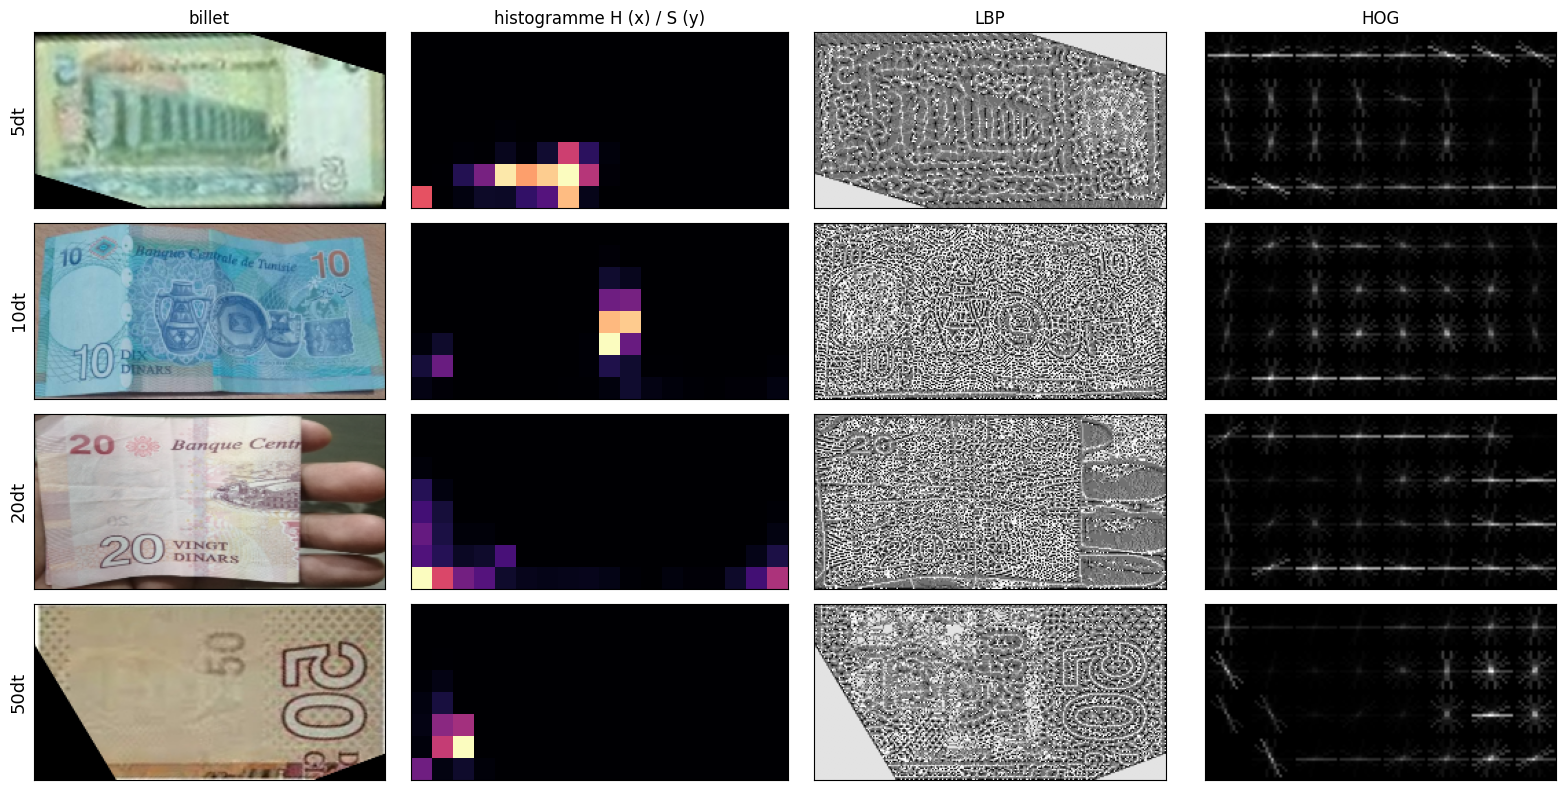

In [31]:
# Caractéristiques d'un billet de chaque classe (recadrage GrabCut)
fig, ax = plt.subplots(4, 4, figsize=(16, 8))
for c in range(4):
    crop = crops['grabcut']['train'][0][np.where(y_train == c)[0][4]]
    gris = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY)
    ax[c, 0].imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
    ax[c, 1].imshow(carac_hsv(crop).reshape(18, 8).T, cmap='magma', origin='lower', aspect='auto')
    ax[c, 2].imshow(local_binary_pattern(gris, 8, 1, 'uniform'), cmap='gray')
    ax[c, 3].imshow(hog(cv2.resize(gris, (128, 64)), pixels_per_cell=(16, 16), visualize=True)[1], cmap='gray')
    ax[c, 0].set_ylabel(CLASSES[c], fontsize=13)
for j, titre in enumerate(['billet', 'histogramme H (x) / S (y)', 'LBP', 'HOG']):
    ax[0, j].set_title(titre)
for a in ax.ravel():
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

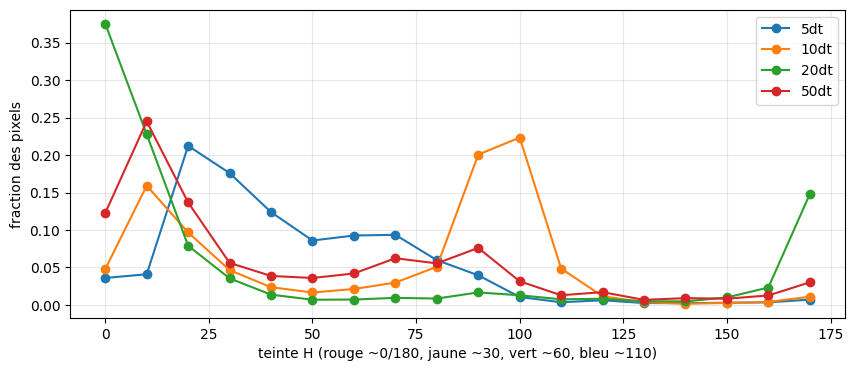

In [32]:
# Profil de teinte moyen par classe : la couleur sépare-t-elle les billets ?
teinte = feats['grabcut']['train']['hsv'].reshape(-1, 18, 8).sum(2)   # somme sur la saturation
plt.figure(figsize=(10, 4))
for c in range(4):
    plt.plot(np.arange(18) * 10, teinte[y_train == c].mean(0), marker='o', label=CLASSES[c])
plt.xlabel('teinte H (rouge ~0/180, jaune ~30, vert ~60, bleu ~110)')
plt.ylabel('fraction des pixels'); plt.legend(); plt.grid(alpha=0.3); plt.show()

**Observations**
- La **couleur** sépare bien 10 DT (bleu, H ≈ 100) et 5 DT (jaune-vert, H ≈ 20-80) ; en revanche **20 DT et 50 DT se recouvrent** dans les teintes rouges (H ≈ 0-20), car la nouvelle série de 50 DT est rose/rouge. La couleur seule ne suffira donc pas pour 50 DT.
- Le **HOG** décrit la structure du billet (chiffres, portrait, bords), mais il n'est pas invariant à une rotation de 180° (billet à l'envers) ni au recto/verso : chaque face et chaque sens doivent être vus à l'entraînement.
- Le **LBP** capte la texture fine d'impression, mais aussi le flou et le grain de la photo.

### Évaluation de la segmentation par la tâche

Pour chaque variante de recadrage, on mesure la précision d'un SVM simple (paramètres par défaut, toutes les caractéristiques) en **validation croisée à 5 plis sur le train** : le test n'est pas utilisé pour ce choix. Si la segmentation isole bien le billet, la précision doit dépasser celle obtenue sur l'image entière.

In [33]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

cv5 = StratifiedKFold(5, shuffle=True, random_state=0)
for meth in feats:
    Xf = np.hstack([feats[meth]['train'][g] for g in GROUPES])
    scores = cross_val_score(make_pipeline(StandardScaler(), SVC()), Xf, y_train, cv=cv5)
    print(f'{meth:8s} : précision CV = {scores.mean():.3f} ± {scores.std():.3f}')

entiere  : précision CV = 0.839 ± 0.038
kmeans   : précision CV = 0.828 ± 0.025
otsu     : précision CV = 0.752 ± 0.029
grabcut  : précision CV = 0.833 ± 0.050


**Conclusion sur la segmentation**
- Otsu dégrade nettement la classification (≈ 0,75) : ses erreurs de segmentation se propagent au classifieur.
- GrabCut, K-means et l'image entière donnent des précisions **équivalentes** (≈ 0,83-0,84) : les écarts sont plus petits que l'écart-type entre plis. La segmentation n'apporte donc pas de gain mesurable ici.
- Explications : (1) près de la moitié des images (web, scans) montrent déjà le billet en plein cadre, la segmentation n'y change rien ; (2) le fond contient lui-même de l'information « parasite » (5 DT est presque toujours un scan sur fond uni) que l'image entière exploite ; (3) les erreurs restantes de GrabCut (billet tronqué, doigt) compensent le gain sur les photos bien segmentées.
- GrabCut repose aussi sur une initialisation aléatoire (K-means interne) : ses résultats varient légèrement d'une exécution à l'autre (± 0,01).
- **Choix retenu** : GrabCut reste la segmentation de la chaîne classique (meilleure qualité de segmentation, billet redressé exploitable par le HOG), et la comparaison avec l'image entière est conservée dans les ablations de la section 4.